## Execute Quantum Circuits on IBM Quantum Hardware

#### Install necessary libraries

In [1]:
%pip install qiskit qiskit_aer pylatexenc
%pip install matplotlib
%pip install qiskit_ibm_runtime


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


#### Step 1: Map the problem to circuit and operators

In this step, we:
- Define a 12-qubit quantum circuit.
- Apply single-qubit gates and multi-qubit entangling gates.
- Create two 6-qubit GHZ constructions.
- Define 66 pairwise \(ZZ\) observables for correlation analysis.

Number of qubits: 12
Number of ZZ observables: 66


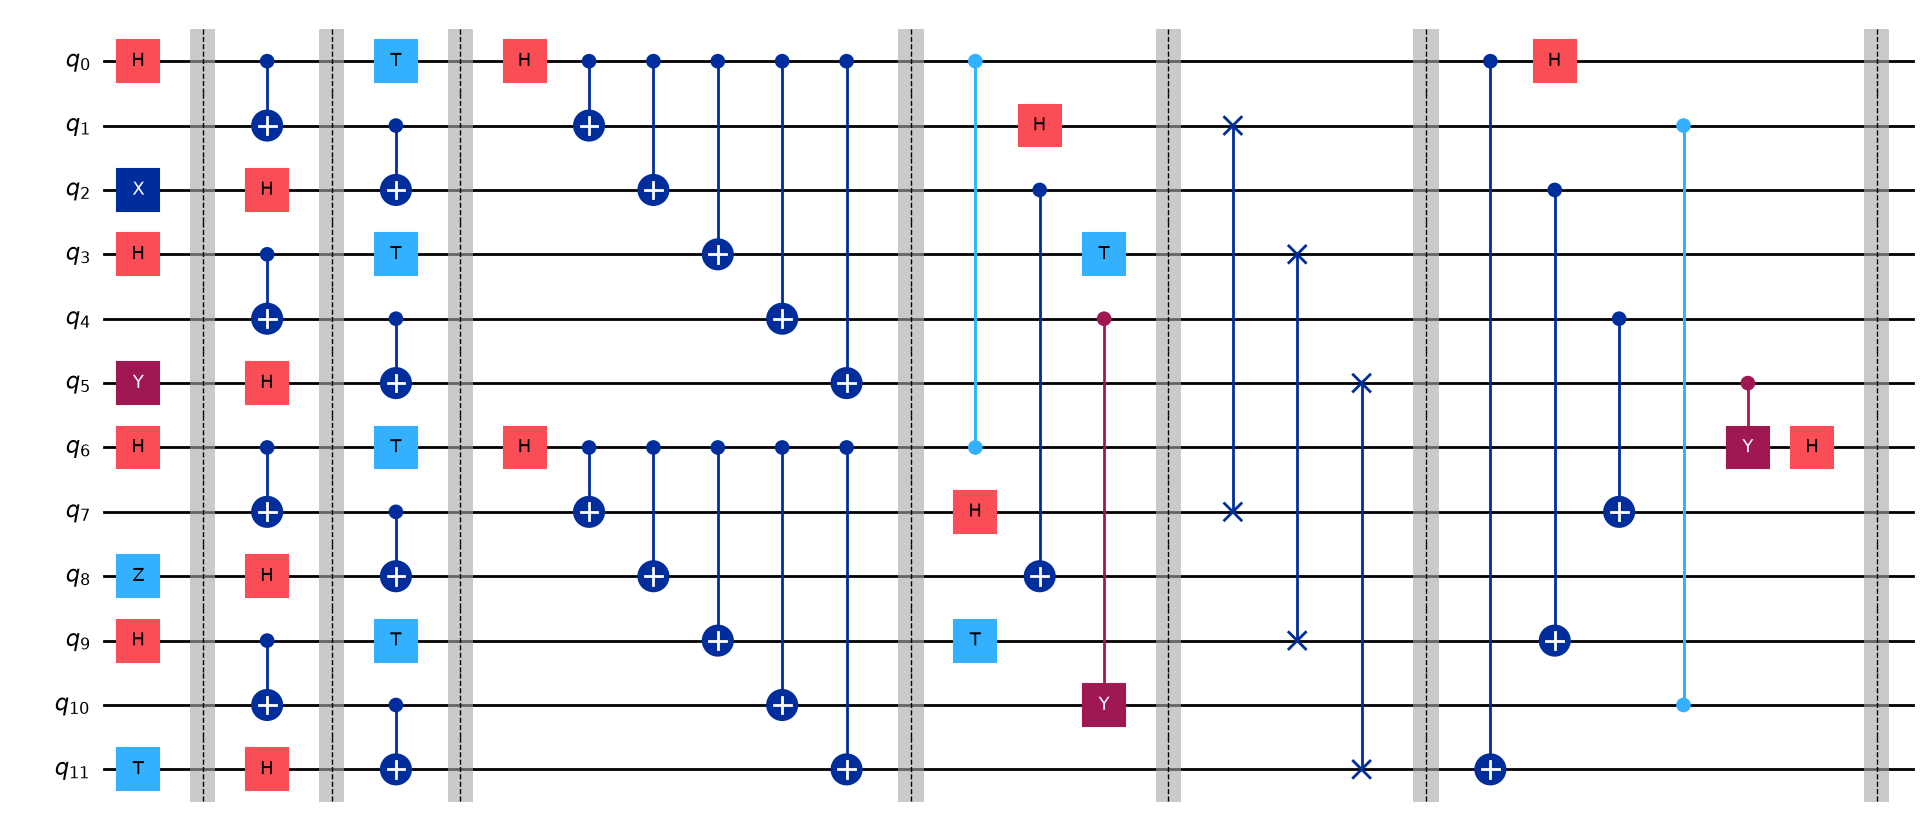

In [2]:
# ==========================================
# STEP 1: MAP THE PROBLEM TO CIRCUIT & OPERATORS
# ==========================================

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp

# Define 12 qubits
n = 12

# Create quantum circuit with 12 qubits and 12 classical bits
qc = QuantumCircuit(n)

# ------------------------------------------
# LAYER 1: INITIAL SUPERPOSITION
# ------------------------------------------

qc.h(0)
qc.h(3)
qc.h(6)
qc.h(9)

qc.x(2)
qc.y(5)
qc.z(8)
qc.t(11)

qc.barrier()

# ------------------------------------------
# LAYER 2: FIRST ENTANGLEMENT NETWORK
# ------------------------------------------

qc.cx(0, 1)
qc.cx(3, 4)
qc.cx(6, 7)
qc.cx(9, 10)

qc.h(2)
qc.h(5)
qc.h(8)
qc.h(11)

qc.barrier()

# ------------------------------------------
# LAYER 3: INTERLEAVED ENTANGLEMENT
# ------------------------------------------

qc.cx(1, 2)
qc.cx(4, 5)
qc.cx(7, 8)
qc.cx(10, 11)

qc.t(0)
qc.t(3)
qc.t(6)
qc.t(9)

qc.barrier()

# ------------------------------------------
# LAYER 4: GHZ STATE GENERATION
# ------------------------------------------

# First 6-qubit GHZ construction
qc.h(0)
for i in range(1, 6):
    qc.cx(0, i)

# Second 6-qubit GHZ construction
qc.h(6)
for i in range(7, 12):
    qc.cx(6, i)

qc.barrier()

# ------------------------------------------
# LAYER 5: CROSS-GROUP INTERACTIONS
# ------------------------------------------

qc.cz(0, 6)
qc.cx(2, 8)
qc.cy(4, 10)

qc.h(1)
qc.t(3)
qc.h(7)
qc.t(9)

qc.barrier()

# ------------------------------------------
# LAYER 6: STATE EXCHANGE
# ------------------------------------------

qc.swap(1, 7)
qc.swap(3, 9)
qc.swap(5, 11)

qc.barrier()

# ------------------------------------------
# LAYER 7: FINAL ENTANGLEMENT
# ------------------------------------------

qc.cx(0, 11)
qc.cx(2, 9)
qc.cx(4, 7)

qc.cz(1, 10)
qc.cy(5, 6)

qc.h(0)
qc.h(6)

qc.barrier()

# ------------------------------------------
# DEFINE ZZ OBSERVABLES
# ------------------------------------------

# All unique qubit pairs: 12C2 = 66
pairs = [
    (i, j)
    for i in range(n)
    for j in range(i + 1, n)
]

operators = [
    SparsePauliOp.from_sparse_list(
        [("ZZ", [i, j], 1.0)],
        num_qubits=n
    )
    for i, j in pairs
]

print("Number of qubits:", n)
print("Number of ZZ observables:", len(operators))

# Draw circuit
qc.draw("mpl", fold=-1)


#### Step 2: Optimize the quantum circuit

Here we use Qiskit's transpile() to compile and optimize the circuit for the target backend.

We will:
- Select AerSimulator as the target backend.
- Apply optimization level 3.
- Compare the original and optimized circuit depth.
- Compare the number of gates before and after optimization.

In [ ]:
# uncomment this section if running on Google Colab
# ensure a secret is already created as QUANTUM_API_KEY

from google.colab import userdata
quantum_api_key = userdata.get('QUANTUM_API_KEY')

if quantum_api_key.strip():
    print("API Key successfully captured!")

In [ ]:
# # uncomment this section if you are running in local computer and provide the key
# from getpass import getpass
# quantum_api_key = getpass("Type your quantum_api_key here: ")

# if quantum_api_key.strip():
#     print("API Key successfully captured!")

API Key successfully captured!


In [4]:
if not quantum_api_key.strip():
    print("API Key is empty. Please try again.")

from qiskit_ibm_runtime import QiskitRuntimeService
service = QiskitRuntimeService(channel="ibm_quantum_platform", token=quantum_api_key)

backend_name = 'ibm_kingston'     # 156 qubits
# backend_name = 'ibm_fez'          # 156 qubits
# backend_name = 'ibm_marrakesh'    # 156 qubits

backend = service.backend(name=backend_name)
backend.num_qubits

qiskit_runtime_service._discover_account:WARNING:2026-11-24 00:17:17,527: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-24 00:17:28,834: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: surnandi. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-24 00:17:28,835: Using instance: surnandi, plan: open


156

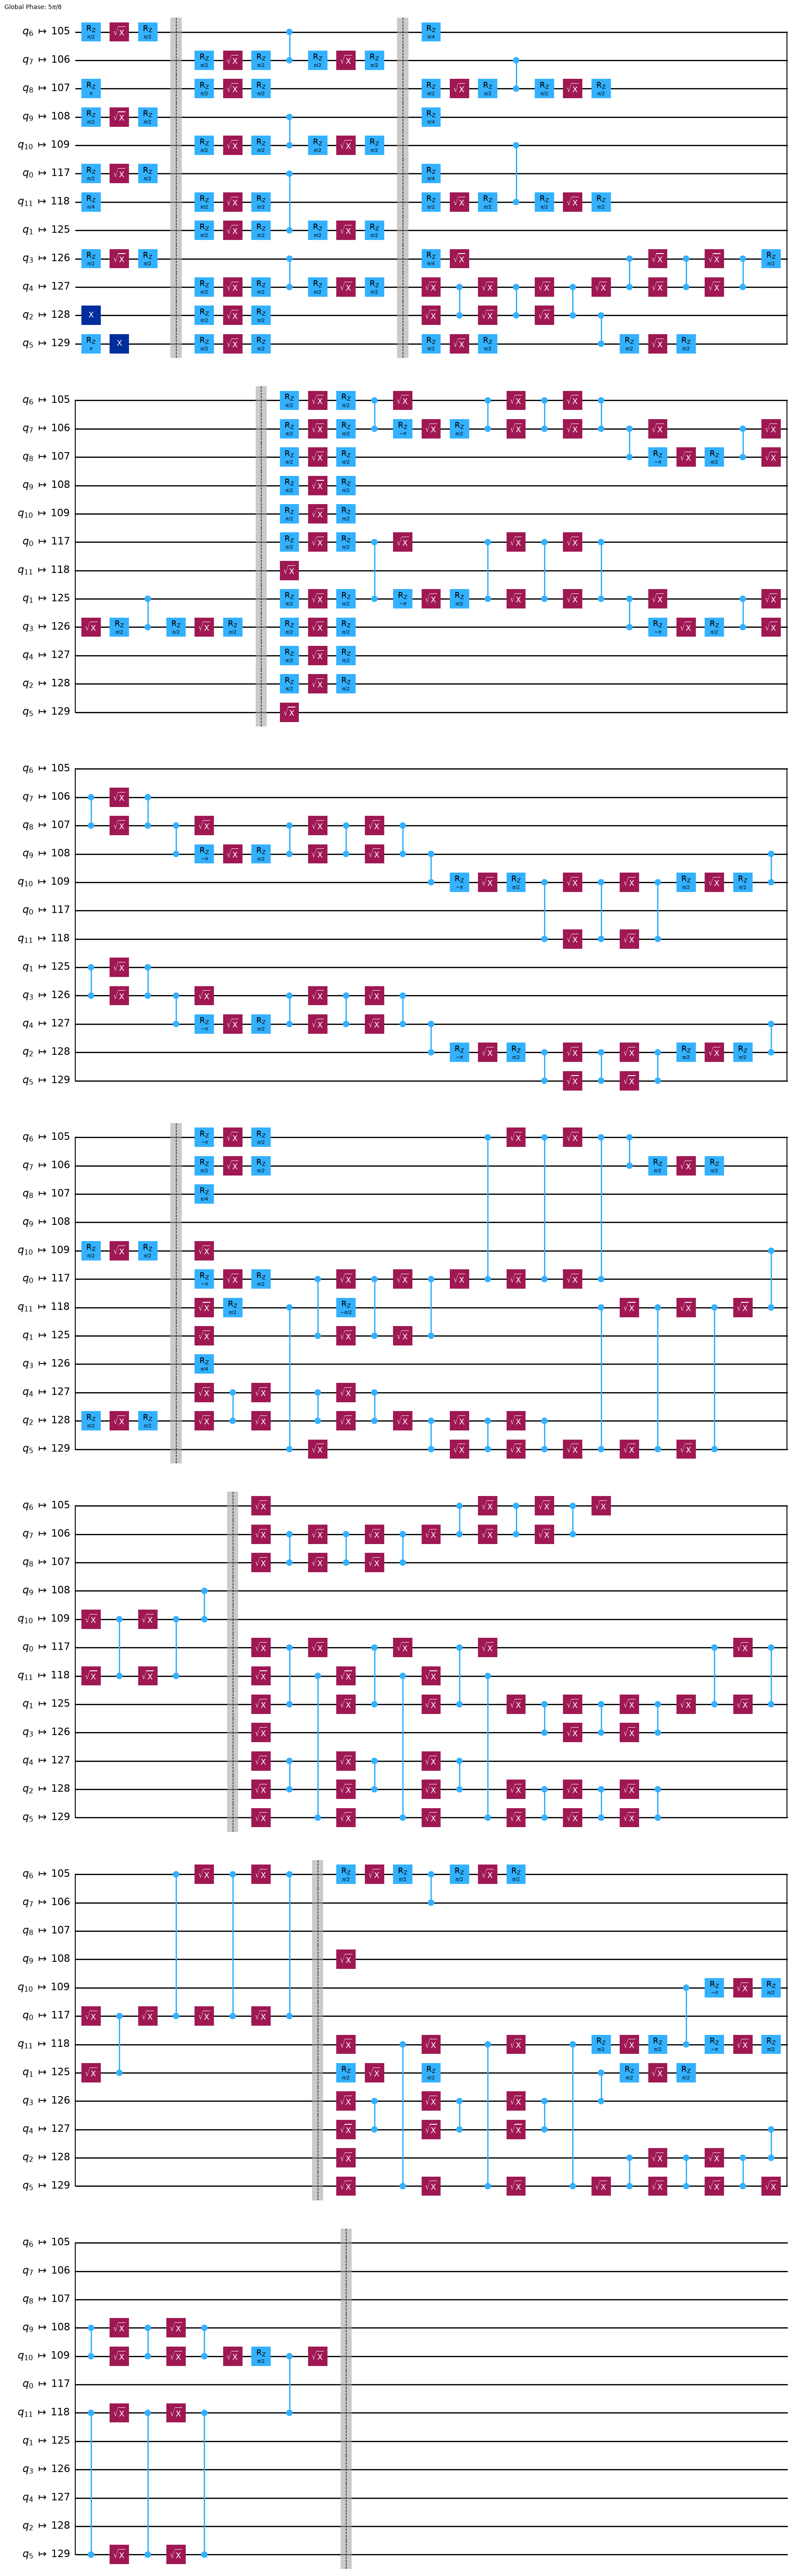

In [9]:
# from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

pass_manager = generate_preset_pass_manager(optimization_level=1, backend=backend)

qc_transpiled = pass_manager.run(qc)
operators_transpiled_list = [op.apply_layout(qc_transpiled.layout) for op in operators]
qc_transpiled.draw("mpl")

#### Step 3: Execute on the backend

Now we execute the optimized circuit using two Qiskit execution paths.

A. Estimator — Calculate quantum correlations

The Estimator calculates the expectation values of our 66 \(ZZ\) observables.

B. AerSimulator — Obtain measurement outcomes

The simulator executes the measured circuit using 4096 shots.

In [10]:
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit_ibm_runtime import EstimatorOptions

options = EstimatorOptions()
options.resilience_level = 1
# options.optimization_level = 1
options.dynamical_decoupling.enable = True
options.dynamical_decoupling.sequence_type = 'XY4'

estimator = Estimator(backend, options=options)
job = estimator.run([(qc_transpiled, operators_transpiled_list)])
job_id = job.job_id()
print(f"Job ID: {job_id}")

qiskit_runtime_service.backends:WARNING:2026-11-24 00:19:27,143: Using instance: surnandi, plan: open


Job ID: dc28lemq4uuc73a4tcgg


#### Step 4: Post-process and plot the results

Now we use Python libraries to process the results returned by Qiskit.

We will create three visualizations.

In [11]:
job = service.job(job_id)

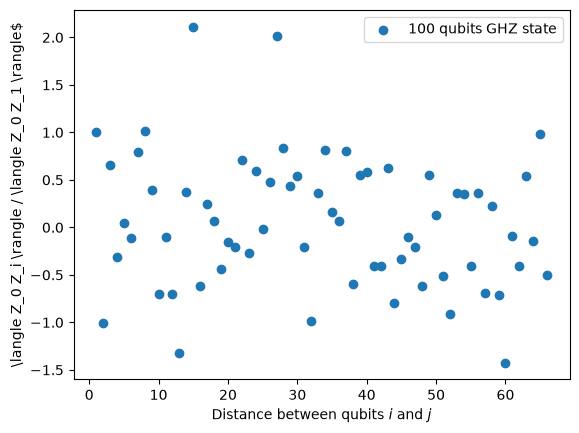

In [ ]:
import matplotlib.pyplot as plt

data = list(range(1, len(operators) + 1))
result = job.result()[0]
values = result.data.evs
values = [v / values[0] for v in values]

plt.scatter(data, values, marker='o', label='GHZ state')
plt.xlabel('Distance between qubits $i$ and $j$')
plt.ylabel(r'\langle Z_0 Z_i \rangle / \langle Z_0 Z_1 \rangle$')
plt.legend()
plt.show()
